# 3 - Survival by CIDER × TMB Combined Groups

**Purpose**: Kaplan-Meier curves for four CIDER (High/Low) × TMB (High/Low)
patient subgroups, demonstrating additive prognostic value.

| | |
|---|---|
| **Inputs** | `CIDER_PROJ_DIR/cpi_ready.rds` |
| **Outputs** | `figs/main_survival_tmb.png`, `supporting_survival_tmb_*.png` |

In [1]:
source(paste0(dirname(getwd()), "/helpers/map.r"))
source(paste0(dirname(getwd()), "/helpers/shortcuts.r"))
source(paste0(dirname(getwd()), "/helpers/config.r"))
source(paste0(dirname(getwd()), "/helpers/themes.r"))

# Ensure figures output directory exists
dir.create(paste0(CIDER_PROJ_DIR, "figs/"), showWarnings = FALSE, recursive = TRUE)

In [2]:
library(survival)
library(survminer)
library(patchwork)


Attaching package: ‘survminer’




The following object is masked from ‘package:survival’:

    myeloma




# 0 - Read data

In [3]:
ready <- readRDS(paste0(CIDER_PROJ_DIR, "cpi_ready.rds"))

# 1 - Figure function

In [ ]:
# KM survival plots stratified by combined CIDER High/Low + TMB High/Low groups.
#
# Colours are passed directly to ggsurvplot via `palette` — avoids conflicts
# with ggsurvplot's internal scale_colour_manual layer.
#
# CRC-MSI has only 2 groups by definition (MSI-H = TMB High), so its legend
# is suppressed to prevent a duplicate from appearing in the collected legend.
# The flat single-row legend is enforced via guide_legend(nrow = 1) on each
# panel before collection, avoiding the patchwork `&` operator.
survival_tmb_plot <- function(data, cdr3_gp, cohort_col, ncols = 3, title = "") {

  df <- data |>
    filter(gp == cdr3_gp) |>
    rename(cohort_label = all_of(cohort_col))

  panel_order <- levels(droplevels(df$cohort_label))

  nested <- df |>
    group_by(cohort_label) |>
    nest()

  panels <- map2(nested$cohort_label, nested$data, function(label, d) {
    fit <- survfit(Surv(osDays, osEvent) ~ combined_group, data = d)

    stripped     <- gsub(paste0("combined_group=", cdr3_gp, " "), "", names(fit$strata))
    clean_labels <- stripped
    gp_palette   <- unname(multi_cols[stripped])

    # Overall log-rank p-value
    cox     <- coxph(Surv(osDays, osEvent) ~ combined_group, data = d)
    p_val   <- summary(cox)$logtest[3]
    p_label <- fmt_pval(p_val)

    # Stratified HRs: CIDER High vs Low within each TMB stratum
    fmt_hr <- function(df, tmb_grp) {
      sub_d <- df |> filter(!is.na(combined_group), grepl(tmb_grp, combined_group))
      if (nrow(sub_d) == 0) return(NULL)
      if (n_distinct(sub_d$combined_group) < 2 || sum(sub_d$osEvent, na.rm = TRUE) < 3) return(NULL)
      cx <- tryCatch(coxph(Surv(osDays, osEvent) ~ group, data = sub_d), error = function(e) NULL)
      if (is.null(cx)) return(NULL)
      hr  <- round(exp(coef(cx)), 2)
      pv  <- summary(cx)$logtest[3]
      pv_label <- gsub("p = ", "p=", fmt_pval(pv))
      paste0("HR=", hr, " (", pv_label, ")")
    }
    hr_tmb_low  <- fmt_hr(d, "TMB Low")
    hr_tmb_high <- fmt_hr(d, "TMB High")
    hr_lines <- paste(
      c(if (!is.null(hr_tmb_low))  paste0("CIDER within TMB Low:  ", hr_tmb_low),
        if (!is.null(hr_tmb_high)) paste0("CIDER within TMB High: ", hr_tmb_high)),
      collapse = "\n"
    )

    p <- ggsurvplot(
      fit, data = d,
      legend.labs = clean_labels,
      palette     = gp_palette,
      pval        = paste0("\nOverall: ", p_label),
      pval.coord  = c(max(d$osDays, na.rm = TRUE) * 0.45, 0.95),
      pval.size   = 3,
      title       = as.character(label)
    )$plot +
      go_theme +
      theme(plot.title = element_text(hjust = 0.5), legend.text = element_text(size = 11)) +
      # Flat single-row legend on every panel — collected legend inherits this
      guides(colour = guide_legend(nrow = 2, byrow = TRUE)) +
      labs(color = NULL) +
      annotate("text",
               x = max(d$osDays, na.rm = TRUE) * 0.45,
               y = 0.82,
               label = hr_lines,
               hjust = 0, vjust = 1,
               size = 2.8, fontface = "plain",
               colour = COL_INK)

    # CRC-MSI only has 2 groups (all patients are TMB-High by definition),
    # so suppress its legend to avoid a mismatched duplicate in the collection
    if (grepl("CRC-MSI", as.character(label))) {
      p <- p + theme(legend.position = "none")
    }
    p
  })
  plot_list <- setNames(panels, as.character(nested$cohort_label))

  # For single-panel figures embedded in combined layouts, bake the title
  # directly into the ggplot so it survives patchwork nesting.
  if (length(plot_list) == 1 && nchar(title) > 0) {
    plot_list[[1]] <- plot_list[[1]] +
      labs(title = title) +
      theme(plot.title = element_text(hjust = 0.5, size = 11, face = "bold"))
  }

  patchwork::wrap_plots(plot_list[panel_order], ncol = ncols, guides = "collect") +
    figure_annotation(if (length(plot_list) > 1) title else NULL,
                      tag = FALSE, legend_pos = "bottom")
}

# 2 - Main figure: T-cell infiltration × TMB

Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


...

Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


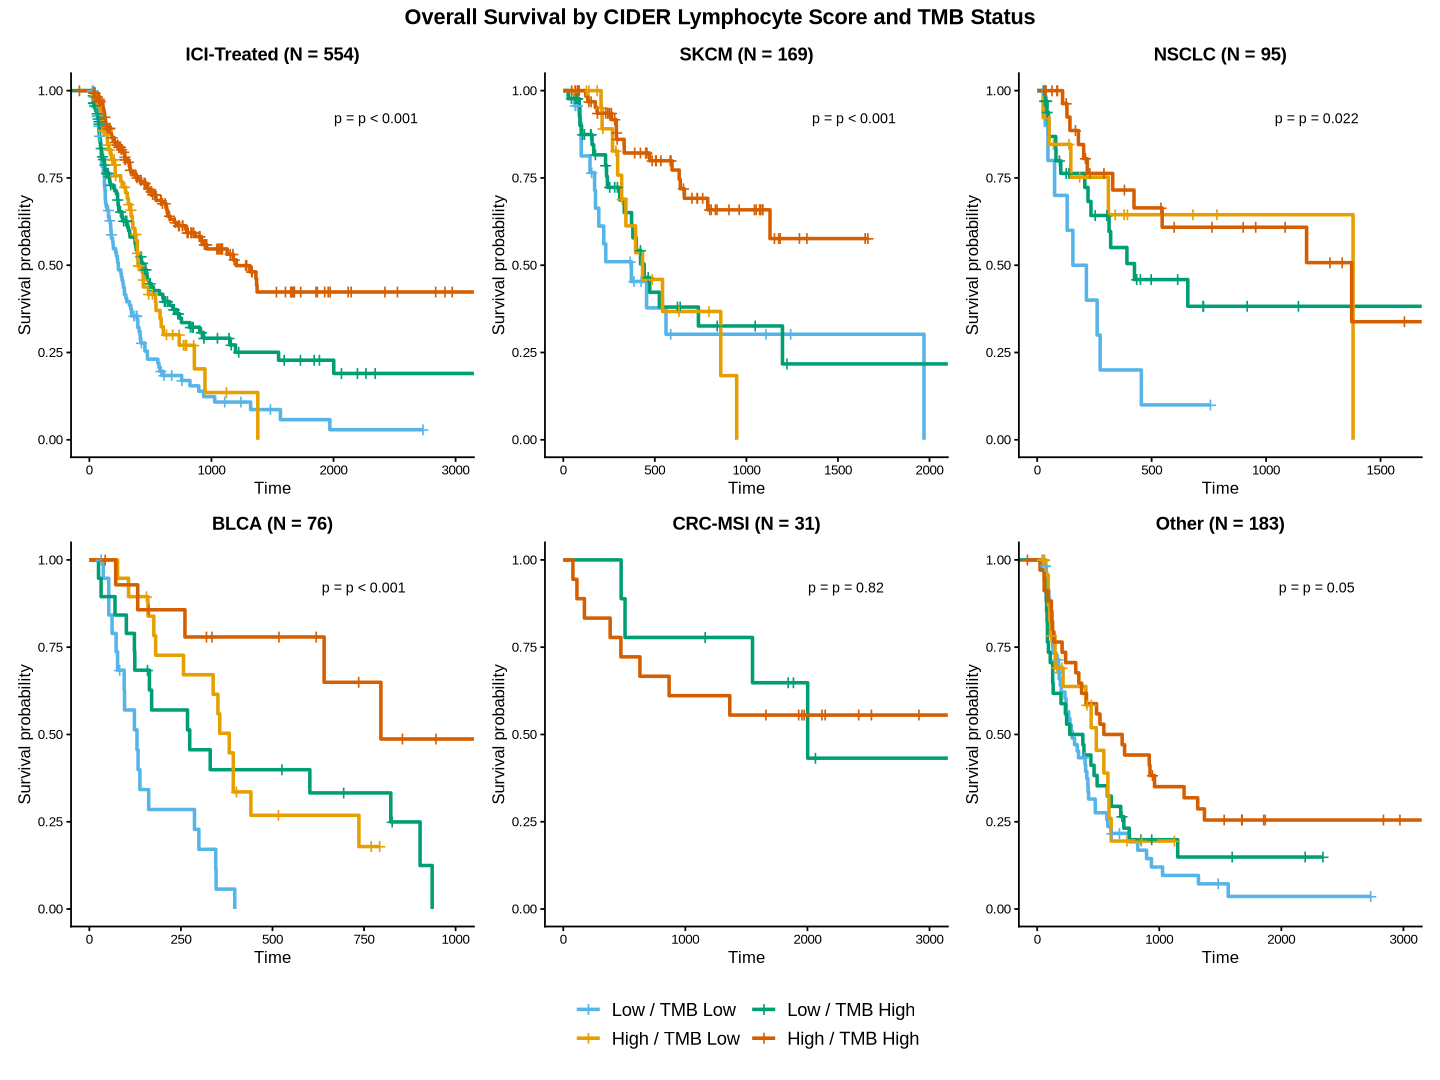

In [5]:
main_survival_tmb <- survival_tmb_plot(
  ready, "T-cell", "cohort_broad_go", ncols = 3,
  title = "Overall Survival by CIDER T-cell Score and TMB Status"
)
set_plot_dims(12, 9); main_survival_tmb


# 2b - ICI-Treated single panel (Figure 5B)

In [ ]:
library(broom)

# Single ICI-Treated panel for Figure 4C.
# Two-factor legend: color = CIDER T-cell Score (High/Low), linetype = TMB (High/Low).
# This separates the primary signal (CIDER) from the secondary stratifier (TMB)
# and connects visually to the CIDER-only survival figure (same color palette).
pan_tcell <- ready |>
  filter(gp == "T-cell", cohort_broad == "ICI-Treated") |>
  mutate(
    # cider_group = group column (median split on cider_score_depth_adj, from 4_base)
    cider_group = group,
    tmb_group   = factor(ifelse(tmb_high == 1, "High", "Low"), levels = c("Low", "High"))
  ) |>
  drop_na(osDays, osEvent, cider_group, tmb_group)

km_fit <- survfit(Surv(osDays / 30.44, osEvent) ~ combined_group, data = pan_tcell)

km_df <- broom::tidy(km_fit) |>
  mutate(
    strata_clean = gsub("combined_group=T-cell ", "", strata),
    cider_group  = factor(
      ifelse(grepl("^High", strata_clean), "High", "Low"),
      levels = c("Low", "High")
    ),
    tmb_group = factor(
      ifelse(grepl("TMB High", strata_clean), "High", "Low"),
      levels = c("Low", "High")
    )
  )

# Overall log-rank p-value
cox_overall <- coxph(Surv(osDays, osEvent) ~ combined_group, data = pan_tcell)
p_label     <- fmt_pval(summary(cox_overall)$logtest[3])

# Stratified HRs: CIDER High vs Low within each TMB stratum
fmt_hr_tmb <- function(d, tmb_grp) {
  sub_d <- d |> filter(tmb_group == tmb_grp)
  if (nrow(sub_d) == 0 || dplyr::n_distinct(sub_d$cider_group) < 2) return(NULL)
  cx <- tryCatch(
    coxph(Surv(osDays, osEvent) ~ cider_group, data = sub_d),
    error = function(e) NULL
  )
  if (is.null(cx)) return(NULL)
  hr <- round(exp(coef(cx)), 2)
  pv <- gsub("p = ", "p=", fmt_pval(summary(cx)$logtest[3]))
  paste0("HR=", hr, " (", pv, ")")
}
hr_tmb_low  <- fmt_hr_tmb(pan_tcell, "Low")
hr_tmb_high <- fmt_hr_tmb(pan_tcell, "High")
hr_lines <- paste(
  c(if (!is.null(hr_tmb_low))  paste0("CIDER within TMB Low:  ", hr_tmb_low),
    if (!is.null(hr_tmb_high)) paste0("CIDER within TMB High: ", hr_tmb_high)),
  collapse = "\n"
)

# Median OS for all four CIDER x TMB quadrants. survminer::surv_median()
# returns NA when a stratum's KM curve never crosses 0.5 survival (median
# not reached), which is reported as "NR" rather than a broken numeric value.
# Printed in full (with 95% CI) to the console for manuscript text, AND a
# compact one-line-per-quadrant version is added directly below the HR
# lines in the plot itself (med_os_short()/median_os_lines below).
med_os <- survminer::surv_median(km_fit) |>
  mutate(
    strata_clean = gsub("combined_group=T-cell ", "", strata),
    cider_group  = factor(ifelse(grepl("^High", strata_clean), "High", "Low"), levels = c("Low", "High")),
    tmb_group    = factor(ifelse(grepl("TMB High", strata_clean), "High", "Low"), levels = c("Low", "High"))
  )

med_os_label <- function(cider_grp, tmb_grp) {
  row <- med_os |> filter(cider_group == cider_grp, tmb_group == tmb_grp)
  if (nrow(row) == 0) return(NA_character_)
  if (is.na(row$median)) return(sprintf("TMB %s / CIDER %s: median OS not reached", tmb_grp, cider_grp))
  sprintf("TMB %s / CIDER %s: median OS = %.1f months (95%% CI %.1f-%.1f)",
          tmb_grp, cider_grp, row$median, row$lower, row$upper)
}
message("\nMedian OS -- Figure 5C, all four CIDER x TMB quadrants (for manuscript text):")
message("  ", med_os_label("Low",  "Low"))
message("  ", med_os_label("High", "Low"))
message("  ", med_os_label("Low",  "High"))
message("  ", med_os_label("High", "High"))

# Compact one-line-per-quadrant version for the in-plot annotation (below the
# HR lines) -- same underlying med_os table, just terser than med_os_label()'s
# console format so four lines of text fit legibly at plot scale.
med_os_short <- function(cider_grp, tmb_grp) {
  row <- med_os |> filter(cider_group == cider_grp, tmb_group == tmb_grp)
  if (nrow(row) == 0) return(NA_character_)
  val <- if (is.na(row$median)) "NR" else sprintf("%.1f mo", row$median)
  sprintf("CIDER %s / TMB %s: %s", cider_grp, tmb_grp, val)
}
median_os_lines <- paste(
  "Median OS:",
  med_os_short("Low",  "Low"),
  med_os_short("High", "Low"),
  med_os_short("Low",  "High"),
  med_os_short("High", "High"),
  sep = "\n"
)

x_max <- max(km_df$time, na.rm = TRUE)

pan_cancer_survival_tmb <- km_df |>
  ggplot(aes(
    x        = time,
    y        = estimate,
    color    = cider_group,
    linetype = tmb_group,
    alpha    = tmb_group,
    group    = strata
  )) +
  geom_step(linewidth = 0.9) +
  scale_color_manual(
    name   = "CIDER T-cell Score",
    values = high_low_color
  ) +
  scale_linetype_manual(
    name   = "TMB",
    values = c("High" = "dashed", "Low" = "solid")
  ) +
  scale_alpha_manual(
    values = c("High" = 1.0, "Low" = 0.75),
    guide  = "none"
  ) +
  coord_cartesian(ylim = c(0, 1)) +
  scale_x_continuous(limits = c(0, NA)) +
  go_theme +
  theme(
    legend.position   = "bottom",
    legend.box        = "vertical",
    legend.margin     = margin(t = 3),
    legend.box.spacing = unit(0, "pt"),
    legend.spacing.y  = unit(-2, "pt"),
    legend.key.width  = unit(1.2, "cm")
  ) +
  annotate("text",
    x = x_max * 0.98, y = 0.97,
    label = paste0("Overall: ", p_label),
    hjust = 1, size = 2.8, colour = COL_INK
  ) +
  annotate("text",
    x = x_max * 0.23, y = 0.90,
    label = hr_lines,
    hjust = 0, vjust = 1, size = 2.8, colour = COL_INK
  ) +
  annotate("text",
    # Shifted 25 percentage points right of the HR-lines/p-value block
    # (0.23 -> 0.48) -- was overlapping the KM curves at 0.23.
    x = x_max * 0.48, y = 0.74,
    label = median_os_lines,
    hjust = 0, vjust = 1, size = 2.6, colour = COL_INK
  ) +
  labs(
    title = "Overall Survival by CIDER Score and TMB Status",
    x     = "Time (months)",
    y     = "Survival Probability"
  )

set_plot_dims(6, 6); pan_cancer_survival_tmb
saveRDS(pan_cancer_survival_tmb, paste0(CIDER_PROJ_DIR, "figs/pan_cancer_survival_tmb.rds"))


# 3 - Supporting: T-cell × TMB

Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


...

Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


Ignoring unknown labels:
• fill : "Strata"
• linetype : "1"


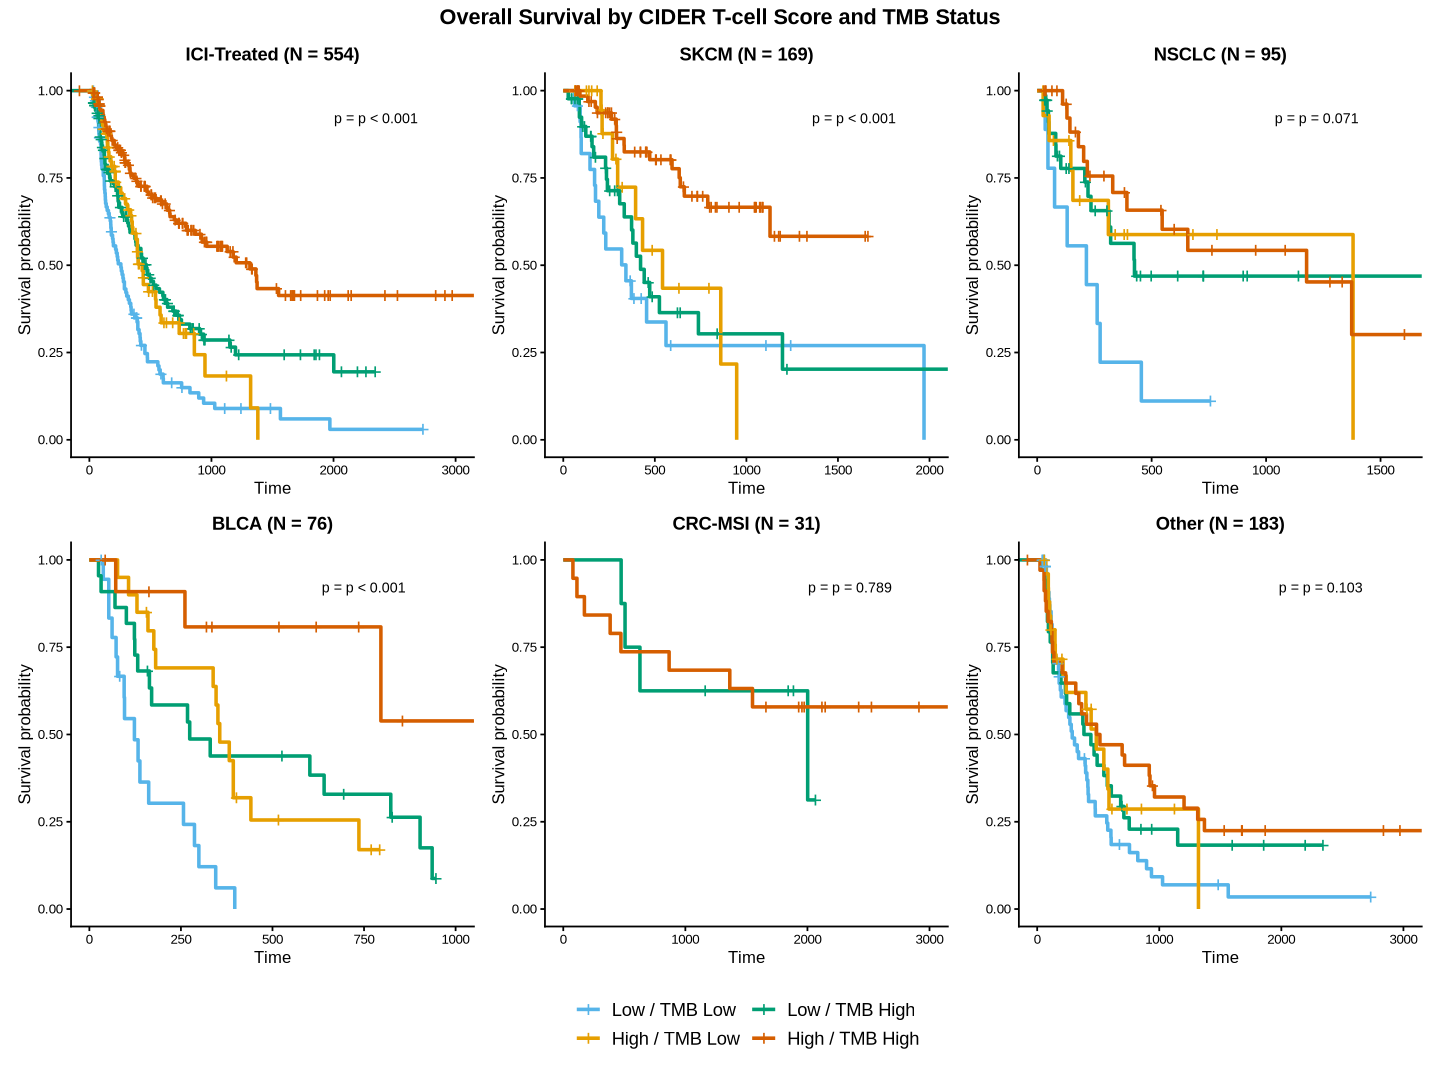

In [7]:
supporting_survival_tmb_tcell <- survival_tmb_plot(
  ready, "T-cell", "cohort_broad_go", ncols = 3,
  title = "Overall Survival by CIDER T-cell Score and TMB Status"
)
set_plot_dims(12, 9); supporting_survival_tmb_tcell

# 5 - Supplementary: Pan-Cancer TMB (3-group) × CIDER T-cell (3-group)

Nine-strata KM plot for the ICI-Treated (Pan-Cancer) cohort.
TMB is split into three groups (<5, 5–10, ≥10 mut/Mb) shown as colours.
CIDER T-cell Score is split into three groups (0–10, 10–40, >40) shown as alpha.

In [ ]:
library(broom)
library(tidyr)

# ── Create groups ─────────────────────────────────────────────────────────────
pan_9group <- ready |>
  filter(gp == "T-cell", cohort_broad == "ICI-Treated") |>
  mutate(
    tmb_raw   = tmbPerMb,
    tmb_group = case_when(
      tmb_raw <  5  ~ "TMB < 5",
      tmb_raw < 10  ~ "TMB 5–10",
      TRUE          ~ "TMB ≥ 10"
    ),
    cider_group = case_when(
      cider_score_depth_adj <  5 ~ "CIDER 0–4",
      cider_score_depth_adj < 21 ~ "CIDER 5–20",
      TRUE                       ~ "CIDER > 20"
    ),
    tmb_group   = factor(tmb_group,   levels = c("TMB < 5", "TMB 5–10", "TMB ≥ 10")),
    cider_group = factor(cider_group, levels = c("CIDER 0–4", "CIDER 5–20", "CIDER > 20")),
    strata_key  = interaction(tmb_group, cider_group, sep = " | ")
  ) |>
  drop_na(osDays, osEvent, tmb_group, cider_group)

# ── Fit KM ────────────────────────────────────────────────────────────────────
km_fit <- survfit(Surv(osDays / 30.44, osEvent) ~ strata_key, data = pan_9group)

# ── Tidy and re-attach group labels ───────────────────────────────────────────
strata_map <- pan_9group |>
  select(strata_key, tmb_group, cider_group) |>
  distinct() |>
  mutate(strata = paste0("strata_key=", strata_key))

km_df <- broom::tidy(km_fit) |>
  left_join(strata_map, by = "strata")

# ── N per stratum for subtitle ─────────────────────────────────────────────────
n_labels <- pan_9group |>
  group_by(tmb_group, cider_group) |>
  summarise(n = n(), .groups = "drop")

# ── Colours: one per CIDER group ─────────────────────────────────────────────
# Faceting by TMB removes the need to encode TMB in colour.
# Three-level ordered low/mid/high CIDER tiers -> COL_NEGATIVE/COL_MID/COL_POSITIVE.
cider_colors <- c("CIDER 0–4"  = COL_NEGATIVE,
                  "CIDER 5–20" = COL_MID,
                  "CIDER > 20" = COL_POSITIVE)

# ── Plot — faceted by TMB group, 3 CIDER lines per panel ─────────────────────
p_9group <- km_df |>
  left_join(n_labels, by = c("tmb_group", "cider_group")) |>
  mutate(cider_label = paste0(cider_group, " (N=", n, ")")) |>
  ggplot(aes(x     = time,
             y     = estimate,
             color = cider_group,
             group = cider_group)) +
  geom_step(linewidth = 0.9) +
  facet_wrap(~ tmb_group, nrow = 1) +
  scale_color_manual(values = cider_colors, name = "CIDER T-cell Score") +
  coord_cartesian(xlim = c(0, 60), ylim = c(0, 1)) +
  go_theme +
  theme(legend.position = "bottom") +
  labs(
    title = "Overall Survival by TMB and CIDER T-cell Score — Pan-Cancer ICI-Treated",
    x     = "Time (months)",
    y     = "Survival Probability"
  )

saveRDS(p_9group, paste0(CIDER_PROJ_DIR, "figs/survival_9group_pan.rds"))
set_plot_dims(10, 5); p_9group

# 5b - Supplementary: Response rates — Pan-Cancer 9-group TMB × CIDER T-cell

Bar plot of ICI response rates for the same 9 groups.
Colours match TMB groups from the KM plot; alpha matches CIDER T-cell level.
Error bars are 95% binomial confidence intervals. N shown inside each bar.

In [ ]:
# ── Colour/alpha scales (shared with KM plot) ────────────────────────────────
# Three-level ordered low/mid/high TMB tiers -> COL_NEGATIVE/COL_MID/COL_POSITIVE
# (same low-to-high convention as cider_colors above).
tmb_colors <- c(
  "TMB < 5"   = COL_NEGATIVE,
  "TMB 5–10"  = COL_MID,
  "TMB ≥ 10"  = COL_POSITIVE
)
cider_alphas <- c(
  "CIDER 0–4"  = 0.35,
  "CIDER 5–20" = 0.70,
  "CIDER > 20" = 1.00
)

# ── Compute response rates with 95% binomial CI ───────────────────────────────
response_rates <- pan_9group |>
  drop_na(responder) |>
  group_by(tmb_group, cider_group) |>
  summarise(
    n_total    = n(),
    n_response = sum(responder == "Responder"),
    .groups    = "drop"
  ) |>
  rowwise() |>
  mutate(
    rate  = n_response / n_total * 100,
    ci    = list(binom.test(n_response, n_total)$conf.int * 100),
    ci_lo = ci[[1]],
    ci_hi = ci[[2]],
    label = paste0(n_response, "/", n_total)
  ) |>
  ungroup() |>
  select(-ci)

# ── Plot ──────────────────────────────────────────────────────────────────────
# CIDER groups on x-axis; faceted by TMB group (ordered low → high).
p_response_9group <- response_rates |>
  ggplot(aes(x = cider_group, y = rate, fill = tmb_group, alpha = cider_group)) +
  geom_col(width = 0.7) +
  geom_errorbar(
    aes(ymin = ci_lo, ymax = ci_hi),
    width = 0.25, linewidth = 0.5, alpha = 1
  ) +
  geom_text(
    aes(y = 2, label = label),
    size = 2.5, vjust = 0, colour = COL_INK, fontface = "bold", alpha = 1
  ) +
  facet_wrap(~ tmb_group, nrow = 1) +
  scale_fill_manual(values  = tmb_colors,   name = "TMB (mut/Mb)") +
  scale_alpha_manual(values = cider_alphas, name = "CIDER T-cell Score") +
  scale_y_continuous(expand = expansion(mult = c(0, 0.1)),
                     labels = function(x) paste0(x, "%")) +
  go_theme +
  theme(legend.position = "right") +
  guides(x = guide_axis(n.dodge = 2)) +
  labs(
    title = "ICI Response Rate by TMB and CIDER T-cell Score — Pan-Cancer ICI-Treated",
    x     = "CIDER T-cell Score Group",
    y     = "Response Rate"
  )

saveRDS(p_response_9group, paste0(CIDER_PROJ_DIR, "figs/response_9group_pan.rds"))
set_plot_dims(9, 4); p_response_9group

# 6 - Supplement: Pan-Cancer CIDER × TMB — Depth-Adjusted Score

Reproduces the ICI-Treated single panel (Figure 5B) using `cider_score_depth_adj`
(depth normalised only, no purity correction) to assess sensitivity of the
CIDER × TMB interaction to the purity correction step.

In [ ]:
# Sensitivity analysis: recompute combined_group using cider_score_adj
# (purity-corrected). The primary Figure 5B uses cider_score_depth_adj via
# the group column in cpi_ready; this version adds purity correction.
ready_purity <- ready |>
  filter(gp == "T-cell") |>
  mutate(
    group_purity = factor(
      case_when(
        ntile(cider_score_adj, 2) == 1 ~ "Low",
        TRUE                           ~ "High"
      ),
      levels = c("Low", "High")
    ),
    combined_group_purity = factor(
      paste0("T-cell ", group_purity, " / TMB ", ifelse(tmb_high == 1, "High", "Low")),
      levels = c("T-cell Low / TMB Low", "T-cell Low / TMB High",
                 "T-cell High / TMB Low", "T-cell High / TMB High")
    )
  )

# Temporarily swap combined_group so survival_tmb_plot works unchanged
ready_purity_swap <- ready_purity |> mutate(combined_group = combined_group_purity)

pan_cancer_survival_tmb_depth <- survival_tmb_plot(
  ready_purity_swap |> filter(cohort_broad == "ICI-Treated"),
  "T-cell", "cohort_broad_go", ncols = 1,
  title = "OS by CIDER Score and TMB Status (Purity Adjusted)"
)
saveRDS(pan_cancer_survival_tmb_depth, paste0(CIDER_PROJ_DIR, "figs/pan_cancer_survival_tmb_depth_adj.rds"))
set_plot_dims(6, 6); pan_cancer_survival_tmb_depth